In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..")))

In [2]:
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

device

'cuda'

In [3]:
import pandas as pd

train = pd.read_parquet("../preprocessed.parquet")

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

numerical_features = [
    "age",
    "study_hours",
    "class_attendance",
    "sleep_hours",
    "study_efficiency",
    "sleep_study_ratio",
]

y = train["target"]
X: pd.DataFrame = train.drop("target", axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler: StandardScaler = StandardScaler().set_output(transform="pandas")
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numerical_features] = scaler.fit_transform(X_train[numerical_features])
X_test_scaled[numerical_features] = scaler.transform(X_test[numerical_features])

print(f"Train: {X_train.shape[0]} rows")
print(f"Test:  {X_test.shape[0]} rows")

Train: 504000 rows
Test:  126000 rows


In [5]:
from sklearn.model_selection import KFold

kf = KFold(n_splits=5, shuffle=True, random_state=42)

In [ ]:
from src.nn.regressor import LightningTabularRegressor
from src.nn.litmlp import LitMLP


def litmlp_fit(
    model: LightningTabularRegressor,
    X_train: pd.DataFrame,
    y_train: pd.DataFrame,
    X_valid: pd.DataFrame,
    y_valid: pd.DataFrame,
):
    return model.fit(X_train, y_train, X_valid, y_valid)


def litmlp_predict(
    model: LightningTabularRegressor,
    X_valid: pd.DataFrame,
):
    return model.predict(X_valid)

In [ ]:
from src.test import test_models_manual

model_specs = {
    "TabMLP": (
        LightningTabularRegressor(
            model=LitMLP,
            hidden_dims=(256, 128, 64),
            dropout=0.1,
            lr=1e-3,
            weight_decay=1e-4,
            batch_size=256,
            max_epochs=100,
            patience=20,
            scheduler_patience=5,
            min_lr=1e-6,
            num_workers=0,
            seed=42,
            numeric_cols=numerical_features,
            device=device,
        ),
        X_train_scaled,
        X_test_scaled,
        litmlp_fit,
        litmlp_predict,
    ),
}

test_predictions, test_errors, test_results = test_models_manual(
    model_specs, y_train, y_test, kf, should_clone=False
)

,Model,Test RMSE,Test MAE
0,TabMLP,8.840737,7.056353


,y_true,TabMLP
364426,51.3,60.560841
224752,50.6,47.683277
110423,79.9,62.449707
272555,55.4,59.435585
199651,50.4,48.599228


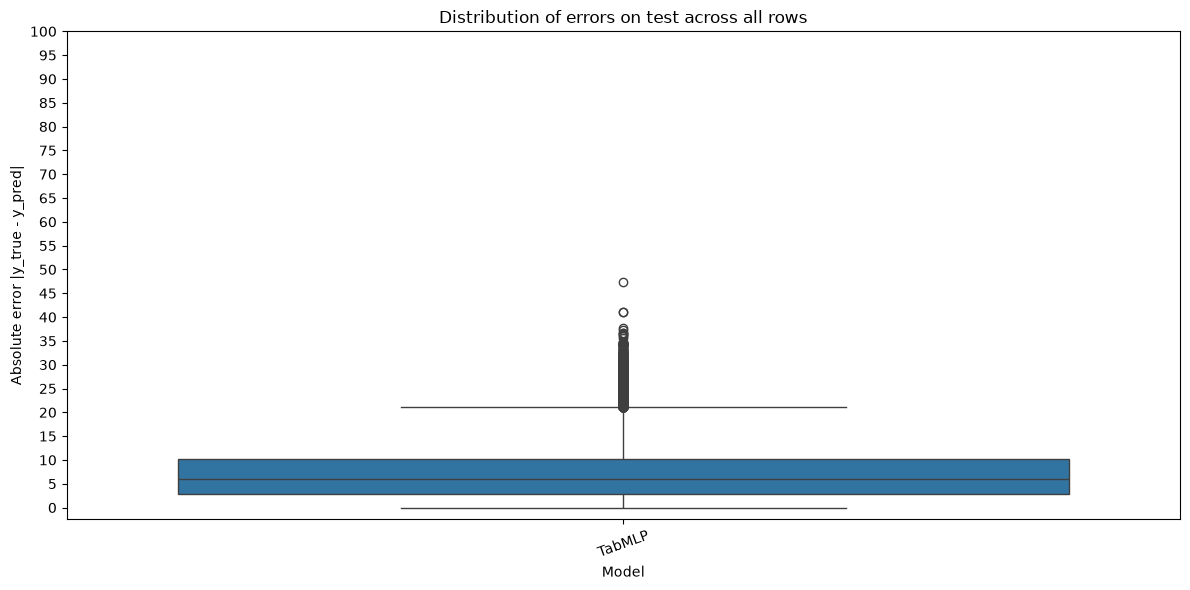

In [8]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

display(test_results)
display(test_predictions.head())

ticks = np.arange(0, 101, 5)

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=test_errors,
    x="Model",
    y="Absolute error",
    hue="Model",
    palette="tab10",
    legend=False,
)

plt.title("Distribution of errors on test across all rows")
plt.xlabel("Model")
plt.ylabel("Absolute error |y_true - y_pred|")
plt.yticks(ticks)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()